In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(
    r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION"
)

REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
FINAL_DIR = PROJECT_ROOT / "outputs" / "final_comparison"

FINAL_DIR.mkdir(parents=True, exist_ok=True)

assert PROJECT_ROOT.exists(), "Project root not found"
assert REPORT_DIR.exists(), "Reports directory not found"

csv_files = sorted(REPORT_DIR.rglob("*.csv"))

inventory = []

for path in csv_files:
    try:
        df = pd.read_csv(path, nrows=5)

        inventory.append({
            "File": str(path.relative_to(PROJECT_ROOT)),
            "Size_MB": round(path.stat().st_size / 1e6, 3),
            "Columns": ", ".join(df.columns.astype(str))
        })

    except Exception as exc:
        inventory.append({
            "File": str(path.relative_to(PROJECT_ROOT)),
            "Size_MB": round(path.stat().st_size / 1e6, 3),
            "Columns": f"ERROR: {exc}"
        })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

inventory_df.to_csv(
    FINAL_DIR / "report_inventory.csv",
    index=False
)

print("Reports discovered:", len(csv_files))
print("Inventory saved:", FINAL_DIR)

,File,Size_MB,Columns
0,outputs\reports\demo_all_resolutions_per_case.csv,0.015,"sample_id, method, resolution, inference_secon..."
1,outputs\reports\demo_all_resolutions_summary.csv,0.006,"method, resolution, inference_seconds_mean, in..."
2,outputs\reports\demo_per_case_metrics_16.csv,0.007,"sample_id, method, resolution, inference_secon..."
3,outputs\reports\demo_per_case_metrics_32.csv,0.008,"sample_id, method, resolution, inference_secon..."
4,outputs\reports\demo_summary_metrics_16.csv,0.004,"method, resolution, inference_seconds_mean, in..."
...,...,...,...
61,outputs\reports\notebook_demo_per_case_metrics...,0.008,"sample_id, method, resolution, inference_secon..."
62,outputs\reports\notebook_demo_results_summary.csv,0.001,"method, resolution, macro_dice_mean, macro_iou..."
63,outputs\reports\notebook_demo_summary_metrics_...,0.004,"method, resolution, inference_seconds_mean, in..."
64,outputs\reports\notebook_demo_summary_metrics_...,0.003,"method, resolution, inference_seconds_mean, in..."


Reports discovered: 66
Inventory saved: D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\outputs\final_comparison


In [2]:
# Optional manual overrides.
# Change these only when automatic discovery does not find the correct report.

REPORT_OVERRIDES = {
    "rf_16": None,
    "rf_32": None,
    "rf_240": None,
    "unet_240": None,
    "paired": None
}


def resolve_override(key):
    value = REPORT_OVERRIDES[key]

    if value is None:
        return None

    path = Path(value)

    if not path.is_absolute():
        path = PROJECT_ROOT / path

    if not path.exists():
        raise FileNotFoundError(path)

    return path


def select_rf_report(resolution):

    key = f"rf_{resolution}"

    override = resolve_override(key)

    if override:
        return override

    preferred = [
        f"msd_test_calibrated_per_slice_{resolution}.csv",
        f"msd_test_per_slice_{resolution}.csv"
    ]

    for name in preferred:
        candidates = list(REPORT_DIR.rglob(name))

        if candidates:
            return candidates[0]

    return None


selected_reports = {
    f"rf_{r}": select_rf_report(r)
    for r in [16, 32, 240]
}

# Discover the U-Net test report.
selected_reports["unet_240"] = resolve_override("unet_240")

if selected_reports["unet_240"] is None:

    unet_candidates = []

    for path in csv_files:

        name = path.name.lower()

        if "test" not in name:
            continue

        if any(x in name for x in ["validation", "train", "uncalibrated"]):
            continue

        try:
            df = pd.read_csv(path)

            method_col = next(
                (c for c in df.columns if str(c).lower() in
                 ["method", "model", "model_name"]),
                None
            )

            if method_col:
                methods = df[method_col].astype(str).str.lower()

                if methods.str.contains("unet|u-net|residual2d", regex=True).any():
                    unet_candidates.append(path)

        except Exception:
            pass

    if len(unet_candidates) == 1:
        selected_reports["unet_240"] = unet_candidates[0]


# Find the paired comparison report.
selected_reports["paired"] = resolve_override("paired")

if selected_reports["paired"] is None:

    paired_candidates = [
        p for p in csv_files
        if "paired" in p.name.lower()
    ]

    if len(paired_candidates) == 1:
        selected_reports["paired"] = paired_candidates[0]


for key, path in selected_reports.items():

    print(
        f"{key:12} : "
        f"{path.relative_to(PROJECT_ROOT) if path else 'NOT FOUND — inspect inventory'}"
    )

rf_16        : outputs\reports\msd_test_calibrated_per_slice_16.csv
rf_32        : outputs\reports\msd_test_calibrated_per_slice_32.csv
rf_240       : outputs\reports\msd_test_calibrated_per_slice_240.csv
unet_240     : NOT FOUND — inspect inventory
paired       : NOT FOUND — inspect inventory


,Model,Resolution,Source,Macro Dice Mean,Macro Dice Std,Macro IoU Mean,Macro IoU Std,Active Macro Dice Mean,Active Macro Dice Std,Active Macro IoU Mean,Active Macro IoU Std
0,Random Forest,16x16,outputs\reports\msd_test_calibrated_per_slice_...,0.594388,0.259988,0.529883,0.259947,0.443053,0.327726,0.357462,0.290326
1,Random Forest,32x32,outputs\reports\msd_test_calibrated_per_slice_...,0.590548,0.265290,0.513179,0.257086,0.487494,0.327530,0.393238,0.288235
2,Random Forest,240x240,outputs\reports\msd_test_calibrated_per_slice_...,0.476972,0.305772,0.389014,0.271537,0.476246,0.315744,0.376282,0.275468


Saved final model metrics.


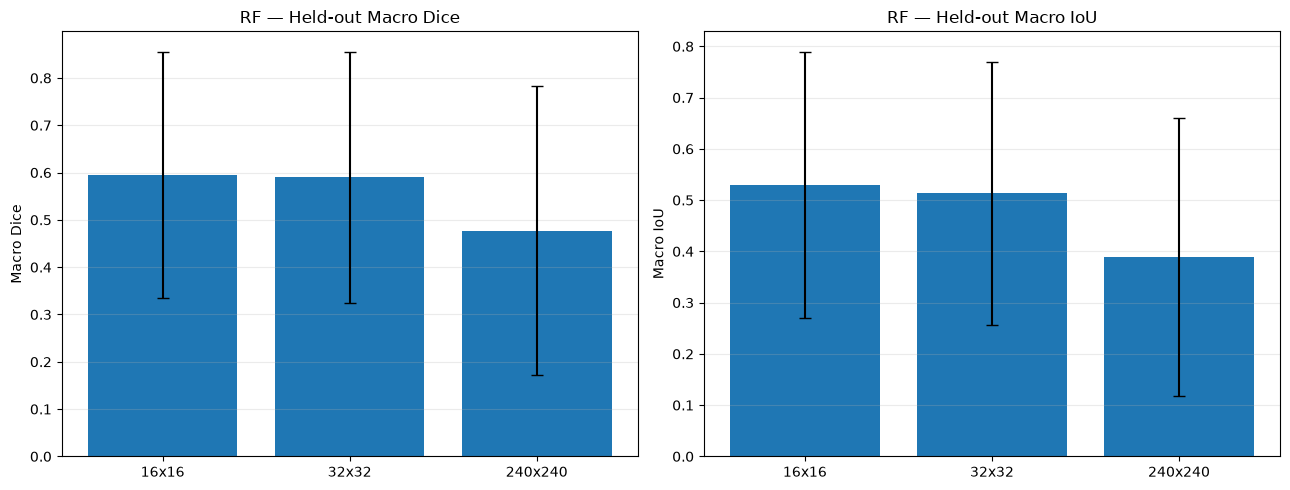

No paired comparison CSV identified. Do not claim a paired RF-versus-U-Net result from separate reports.
\nFINAL OUTPUT DIRECTORY:
D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION\outputs\final_comparison


In [3]:
def find_col(df, names):

    mapping = {str(c).lower(): c for c in df.columns}

    for name in names:

        if name.lower() in mapping:
            return mapping[name.lower()]

    return None


def filter_model(df, family):

    method_col = find_col(
        df,
        ["method", "model", "model_name", "algorithm"]
    )

    if method_col is None:
        return df.copy()

    names = df[method_col].astype(str).str.lower()

    if family == "RF":
        mask = names.str.contains(
            r"random\s*forest|randomforest|\brf\b",
            regex=True
        )
    else:
        mask = names.str.contains(
            r"unet|u-net|residual\s*2d",
            regex=True
        )

    return df.loc[mask].copy()


METRIC_COLUMNS = {
    "Macro Dice": (
        ["macro_dice_mean"],
        ["macro_dice_std"],
        ["macro_dice"]
    ),

    "Macro IoU": (
        ["macro_iou_mean"],
        ["macro_iou_std"],
        ["macro_iou"]
    ),

    "Active Macro Dice": (
        [
            "macro_dice_present_gt_mean",
            "macro_dice_active_mean"
        ],
        [
            "macro_dice_present_gt_std",
            "macro_dice_active_std"
        ],
        [
            "macro_dice_present_gt",
            "macro_dice_active"
        ]
    ),

    "Active Macro IoU": (
        [
            "macro_iou_present_gt_mean",
            "macro_iou_active_mean"
        ],
        [
            "macro_iou_present_gt_std",
            "macro_iou_active_std"
        ],
        [
            "macro_iou_present_gt",
            "macro_iou_active"
        ]
    )
}


def get_metric(df, metric):

    mean_names, std_names, raw_names = METRIC_COLUMNS[metric]

    mean_col = find_col(df, mean_names)
    std_col = find_col(df, std_names)

    if mean_col:

        values = pd.to_numeric(
            df[mean_col], errors="coerce"
        ).dropna()

        if not values.empty:

            mean = values.mean()

            std = None

            if std_col:
                std_values = pd.to_numeric(
                    df.loc[values.index, std_col],
                    errors="coerce"
                ).dropna()

                if not std_values.empty:
                    std = std_values.mean()

            return mean, std

    raw_col = find_col(df, raw_names)

    if raw_col:

        values = pd.to_numeric(
            df[raw_col], errors="coerce"
        ).dropna()

        if not values.empty:

            return (
                values.mean(),
                values.std(ddof=1) if len(values) > 1 else 0.0
            )

    return None, None


def summarize_report(path, family, resolution):

    if path is None:
        return None

    df = pd.read_csv(path, low_memory=False)

    df = filter_model(df, family)

    if df.empty:
        print("No matching model row:", path.name)
        return None

    result = {
        "Model": (
            "Random Forest" if family == "RF"
            else "Residual 2D U-Net"
        ),
        "Resolution": f"{resolution}x{resolution}",
        "Source": str(path.relative_to(PROJECT_ROOT))
    }

    for metric in METRIC_COLUMNS:

        mean, std = get_metric(df, metric)

        result[f"{metric} Mean"] = mean
        result[f"{metric} Std"] = std

    if result["Macro Dice Mean"] is None:
        print("Metric schema not recognized:", path.name)
        return None

    return result


records = []

for resolution in [16, 32, 240]:

    record = summarize_report(
        selected_reports[f"rf_{resolution}"],
        "RF",
        resolution
    )

    if record:
        records.append(record)


unet_record = summarize_report(
    selected_reports["unet_240"],
    "UNet",
    240
)

if unet_record:
    records.append(unet_record)


final_table = pd.DataFrame(records)

display(final_table)

if not final_table.empty:

    final_table.to_csv(
        FINAL_DIR / "final_model_metrics.csv",
        index=False
    )

    print("Saved final model metrics.")


# RF resolution comparison
rf_table = final_table[
    final_table["Model"] == "Random Forest"
].dropna(subset=["Macro Dice Mean"])

if not rf_table.empty:

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].bar(
        rf_table["Resolution"],
        rf_table["Macro Dice Mean"],
        yerr=rf_table["Macro Dice Std"].fillna(0),
        capsize=4
    )

    axes[0].set_title("RF — Held-out Macro Dice")
    axes[0].set_ylabel("Macro Dice")
    axes[0].set_ylim(bottom=0)
    axes[0].grid(axis="y", alpha=0.25)

    iou_table = rf_table.dropna(subset=["Macro IoU Mean"])

    axes[1].bar(
        iou_table["Resolution"],
        iou_table["Macro IoU Mean"],
        yerr=iou_table["Macro IoU Std"].fillna(0),
        capsize=4
    )

    axes[1].set_title("RF — Held-out Macro IoU")
    axes[1].set_ylabel("Macro IoU")
    axes[1].set_ylim(bottom=0)
    axes[1].grid(axis="y", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        FINAL_DIR / "rf_resolution_comparison.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()


# Separate paired model comparison, if an actual paired report exists.
paired_path = selected_reports["paired"]

if paired_path:

    paired_df = pd.read_csv(paired_path)

    display(paired_df)

    paired_df.to_csv(
        FINAL_DIR / "paired_rf_unet_comparison.csv",
        index=False
    )

    print("Paired comparison saved.")

else:

    print(
        "No paired comparison CSV identified. "
        "Do not claim a paired RF-versus-U-Net result from separate reports."
    )


print("\\nFINAL OUTPUT DIRECTORY:")
print(FINAL_DIR)

In [4]:
from pathlib import Path

ROOT = Path(
    r"D:\Projects\CAPSTONE\QIP\PROJECT_QUANTUM_V3_SUBMISSION"
)

extensions = {
    ".csv", ".json", ".jsonl",
    ".xlsx", ".xls", ".parquet"
}

excluded = {
    ".venv", "__pycache__", ".git",
    "node_modules", ".ipynb_checkpoints"
}

for folder in ["outputs", "artifacts", "configs", "scripts", "notebooks", "data"]:

    base = ROOT / folder

    if not base.exists():
        continue

    print(f"\n{'='*80}\n{folder.upper()}\n{'='*80}")

    for path in sorted(base.rglob("*")):

        if not path.is_file():
            continue

        if any(part in excluded for part in path.parts):
            continue

        if path.suffix.lower() not in extensions:
            continue

        print(
            f"{path.relative_to(ROOT)}"
            f"  |  {path.stat().st_size / 1024:.1f} KB"
        )


OUTPUTS
outputs\final_comparison\final_model_metrics.csv  |  0.8 KB
outputs\final_comparison\report_inventory.csv  |  64.6 KB
outputs\reports\demo_all_resolutions_per_case.csv  |  14.5 KB
outputs\reports\demo_all_resolutions_summary.csv  |  6.2 KB
outputs\reports\demo_per_case_metrics_16.csv  |  7.1 KB
outputs\reports\demo_per_case_metrics_32.csv  |  7.6 KB
outputs\reports\demo_summary_metrics_16.csv  |  3.5 KB
outputs\reports\demo_summary_metrics_32.csv  |  3.3 KB
outputs\reports\msd_experiment_summary.json  |  123.6 KB
outputs\reports\msd_patient_split.json  |  17.1 KB
outputs\reports\msd_probability_calibration_summary.json  |  57.3 KB
outputs\reports\msd_test_calibrated_per_patient_16.csv  |  156.8 KB
outputs\reports\msd_test_calibrated_per_patient_240.csv  |  173.7 KB
outputs\reports\msd_test_calibrated_per_patient_32.csv  |  163.5 KB
outputs\reports\msd_test_calibrated_per_slice_16.csv  |  1011.6 KB
outputs\reports\msd_test_calibrated_per_slice_240.csv  |  1238.1 KB
outputs\repo